Phase 1: Importing packages and libraries

In [1]:
!pip3 install transformers datasets accelerate torch scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Phase 2: Import Libraries

In [2]:
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

c:\Users\91709\Documents\Bindu\DS-C-WE-E-B123\my_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Phase 3: Load Dataset

In [3]:
train = pd.read_csv(
    r"C:/Users/91709/Documents/Bindu/DS-C-WE-E-B123/GUVI Projects/Financial_Sentiment_Analysis/data/sent_train.csv"
)

valid = pd.read_csv(
    r"C:/Users/91709/Documents/Bindu/DS-C-WE-E-B123/GUVI Projects/Financial_Sentiment_Analysis/data/sent_valid.csv"
)

Phase 4: Check Labels

In [4]:
train["label"].value_counts()

label
2    6178
1    1923
0    1442
Name: count, dtype: int64

Phase 5: Minimal Text Cleaning

In [5]:
import re

def bert_clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train["text"] = train["text"].apply(bert_clean)
valid["text"] = valid["text"].apply(bert_clean)

In [6]:
train.head(5)

,text,label
0,$bynd - jpmorgan reels in expectations on beyo...,0
1,$ccl $rcl - nomura points to bookings weakness...,0
2,"$cx - cemex cut at credit suisse, j.p. morgan ...",0
3,$ess: btig research cuts to neutral,0
4,$fnko - funko slides after piper jaffray pt cut,0


Phase 6: Convert to Hugging Face Dataset

In [7]:
train_dataset = Dataset.from_pandas(train[["text","label"]])
valid_dataset = Dataset.from_pandas(valid[["text","label"]])
train_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 9543
})

Phase 7: Load FinBERT Model

In [8]:
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer Loaded Successfully")

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
print("Model Loaded Successfully")

print(type(tokenizer))
print(type(model))

c:\Users\91709\Documents\Bindu\DS-C-WE-E-B123\my_env\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\91709\.cache\huggingface\hub\models--ProsusAI--finbert. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tokenizer Loaded Successfully


c:\Users\91709\Documents\Bindu\DS-C-WE-E-B123\my_env\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\91709\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 882.51it/s]

Model Loaded Successfully
<class 'transformers.models.bert.tokenization_bert.BertTokenizer'>
<class 'transformers.models.bert.modeling_bert.BertForSequenceClassification'>


Phase 8: FinBERT Tokenization

In [9]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_valid = valid_dataset.map(tokenize_function, batched=True)
tokenized_train

Map: 100%|██████████| 2388/2388 [00:00<00:00, 12467.43 examples/s]


Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 9543
})

In [10]:
tokenized_train[0]

{'text': '$bynd - jpmorgan reels in expectations on beyond meat',
 'label': 0,
 'input_ids': [101,
  1002,
  2011,
  4859,
  1011,
  16545,
  5302,
  16998,
  15934,
  2015,
  1999,
  10908,
  2006,
  3458,
  6240,
  102,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0],
 'token_type_ids': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,

Phase 9: Convert Dataset to PyTorch Format

In [11]:
tokenized_train.set_format("torch", columns=["input_ids", "attention_mask", "label"])
tokenized_valid.set_format("torch", columns=["input_ids", "attention_mask", "label"])
tokenized_train[0]

{'label': tensor(0),
 'input_ids': tensor([  101,  1002,  2011,  4859,  1011, 16545,  5302, 16998, 15934,  2015,
          1999, 10908,  2006,  3458,  6240,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,   

Phase 10: Evaluation Metrics Function

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits,axis=-1)
    precision, recall, f1, _ = \
        precision_recall_fscore_support(labels, predictions, average="macro")
    accuracy = accuracy_score(labels, predictions)
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

Phase 11: Define Training Arguments and Create Trainer

In [16]:
from transformers import TrainingArguments
from transformers import Trainer

training_args = TrainingArguments(
    output_dir="./finbert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    weight_decay=0.01,
    load_best_model_at_end=True)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    compute_metrics=compute_metrics)

Phase 12: Fine-Tune FinBERT

In [17]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.429543,0.357419,0.872278,0.832345,0.817453,0.824461


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.10it/s]


TrainOutput(global_step=1193, training_loss=0.4315872767944848, metrics={'train_runtime': 19630.8255, 'train_samples_per_second': 0.486, 'train_steps_per_second': 0.061, 'total_flos': 627722836344576.0, 'train_loss': 0.4315872767944848, 'epoch': 1.0})

In [18]:
predictions = trainer.predict(
    tokenized_valid
)

c:\Users\91709\Documents\Bindu\DS-C-WE-E-B123\my_env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [19]:
y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

y_true = predictions.label_ids

In [20]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.75      0.75      0.75       347
           1       0.84      0.78      0.81       475
           2       0.91      0.93      0.92      1566

    accuracy                           0.87      2388
   macro avg       0.83      0.82      0.82      2388
weighted avg       0.87      0.87      0.87      2388



In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

cm

array([[ 259,   20,   68],
       [  26,  369,   80],
       [  60,   51, 1455]])

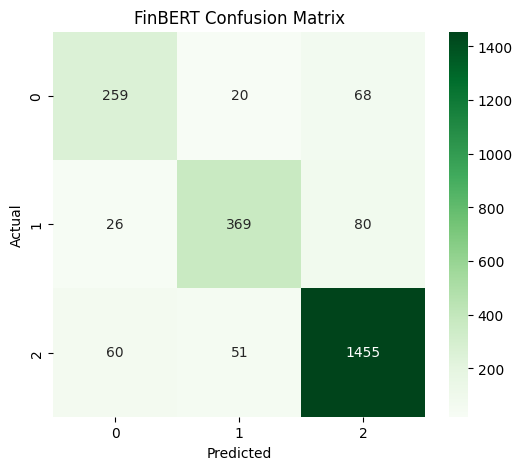

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FinBERT Confusion Matrix")

plt.show()


In [23]:
trainer.save_model(
    "finbert_model"
)
tokenizer.save_pretrained(
    "finbert_model"
)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.35it/s]


('finbert_model\\tokenizer_config.json', 'finbert_model\\tokenizer.json')

In [24]:
comparison_df = pd.DataFrame({

    "Model": [
        "RNN",
        "GRU",
        "LSTM",
        "FinBERT"
    ],

    "F1 Score": [
        0.3832,
        0.6880,
        0.7073,
        0.8245
    ]
})

comparison_df

,Model,F1 Score
0,RNN,0.3832
1,GRU,0.6880
2,LSTM,0.7073
3,FinBERT,0.8245


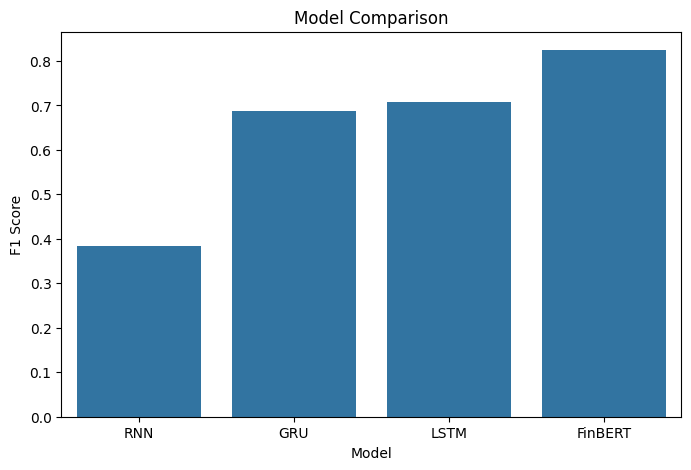

In [25]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="F1 Score"
)

plt.title(
    "Model Comparison"
)

plt.show()

In [26]:
trainer.save_model("finbert_model")

tokenizer.save_pretrained(
    "finbert_model"
)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.70it/s]


('finbert_model\\tokenizer_config.json', 'finbert_model\\tokenizer.json')